In [1]:
from astropy.table import *
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from astropy.table import hstack
import os
import seaborn as sns
from scipy.stats import binned_statistic
import matplotlib
import matplotlib.backends.backend_pdf
import matplotlib.gridspec as gridspec
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from scipy.stats import gaussian_kde

from datetime import datetime

plt.rc('font', family='serif'), plt.rc('xtick', labelsize=18), plt.rc('ytick', labelsize=18)
plt.rcParams['savefig.dpi'] = 300
plt.rc('text',usetex=True)
matplotlib.rcParams['xtick.direction'] = 'in'
matplotlib.rcParams['ytick.direction'] = 'in'
np.set_printoptions(precision=3)

In [4]:
cat = Table.read('/Users/lejay/research/lephare_dev/my_code/graham_output_cats_new/pcat_COSMOS_deep_cat_out_nomaglimit_nonir_il_nz_prior_formass_sfq_added.fits')
cat = cat[cat['inside_u'] == True]
cat = cat[cat['inside_hsc'] == True]
cat = cat[cat['isStar']==False]
cat = cat[cat['isCompact']==False]
cat = cat[cat['i_compact_flag']==False]
cat = cat[cat['snr_i']>3]
cat = cat[cat['snr_r']>1.5]
cat = cat[cat['snr_z']>1.5]
cat = cat[cat['i_cmodel']>0]


Linear Fit Coefficients: [-1.002 34.274]
24.756614412369398 23.754751035085352


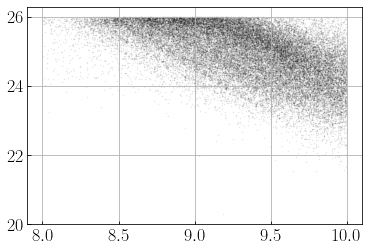

In [50]:
# redshift cut
cat_z = cat[cat['Z_COMBINE']>1.4]
cat_z = cat_z[cat_z['Z_COMBINE']<1.5]

# mass cut
cat_m = cat_z[cat_z['MASS_MED']>8.0]
cat_m = cat_m[cat_m['MASS_MED']<10]

# mass vs i-mag plot
plt.scatter(cat_m['MASS_MED'],cat_m['i'],s=0.2,color='k',alpha=0.1)
plt.grid()

# show polynomial fit
coefficients = np.polyfit(cat_m['MASS_MED'], cat_m['i'], 1)
print("Linear Fit Coefficients:", coefficients)
p=np.poly1d(coefficients)

# plt.plot(cat_m['MASS_MED'], p(cat_m['MASS_MED']), label='Linear Fit', color='red')
# plt.legend()
# plt.show()

print(p(9.5),p(10.5))